In [1]:
import json
import sys
import warnings
from pathlib import Path

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")

train = pd.read_csv("../data/processed/train.csv", parse_dates=["StartDatetime", "EndDatetime"])
test = pd.read_csv("../data/processed/test.csv", parse_dates=["StartDatetime", "EndDatetime"])

with open("../models/feature_columns.json") as file:
    FEATURES = json.load(file)["features"]

regressor = joblib.load("../models/best_regressor.pkl")
classifier = joblib.load("../models/best_classifier.pkl")
print(type(regressor).__name__, "|", type(classifier).__name__)

X_train = train[FEATURES]
# SHAP on 2,000 sessions is plenty for stable plots and keeps it fast
X_explain = test[FEATURES].sample(2000, random_state=42)

LGBMRegressor | LGBMClassifier


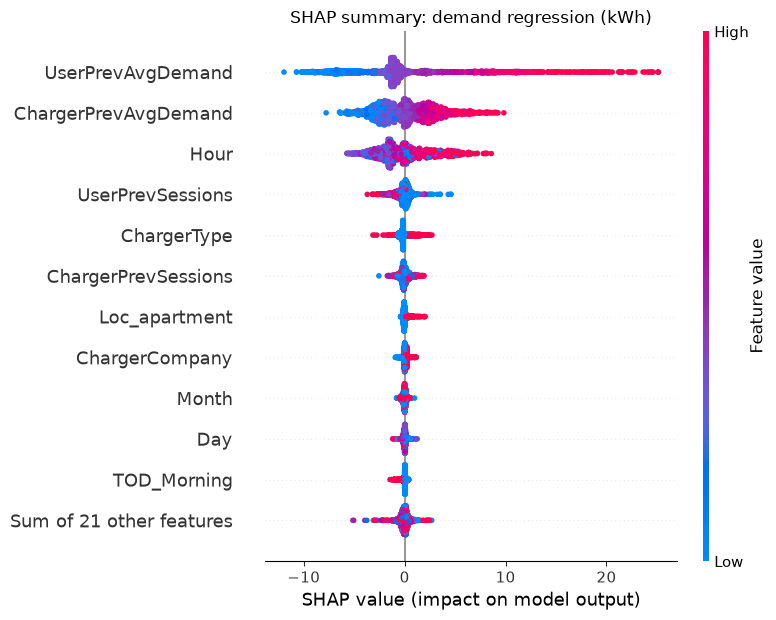

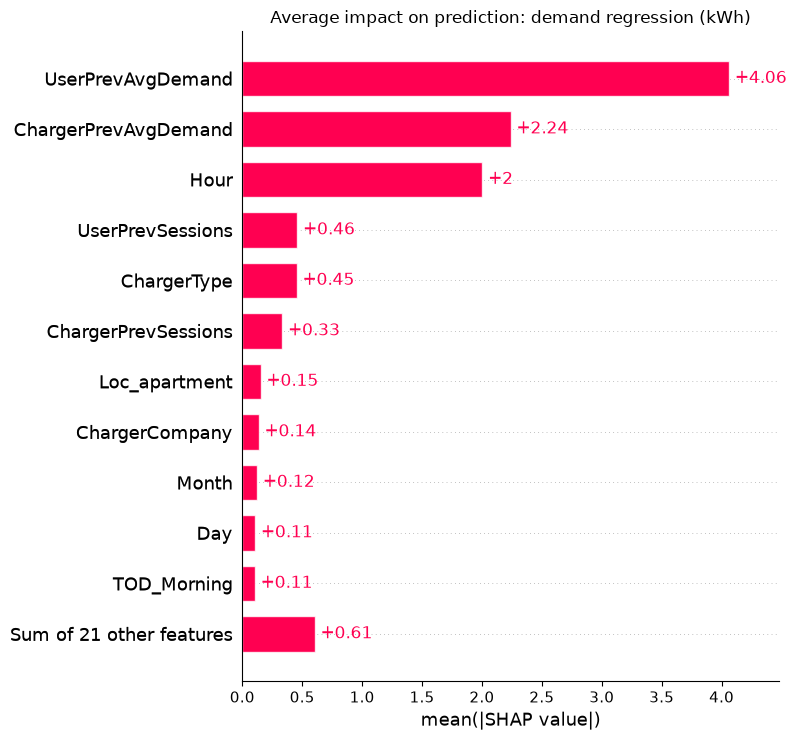

UserPrevAvgDemand       4.06
ChargerPrevAvgDemand    2.24
Hour                    2.00
UserPrevSessions        0.46
ChargerType             0.45
ChargerPrevSessions     0.33
Loc_apartment           0.15
ChargerCompany          0.14
dtype: float64


In [2]:
def explain_globally(model, X, title, file_prefix):
    """Compute SHAP values and save two global plots. Returns the SHAP Explanation object."""
    explainer = shap.TreeExplainer(model)
    explanation = explainer(X)

    # Some versions return one layer per class for classifiers; keep the "High Demand" layer
    if explanation.values.ndim == 3:
        explanation = explanation[:, :, 1]

    plt.figure()
    shap.plots.beeswarm(explanation, max_display=12, show=False)
    plt.title(f"SHAP summary: {title}")
    plt.tight_layout()
    plt.savefig(f"../docs/figures/{file_prefix}_beeswarm.png", dpi=150, bbox_inches="tight")
    plt.show()

    plt.figure()
    shap.plots.bar(explanation, max_display=12, show=False)
    plt.title(f"Average impact on prediction: {title}")
    plt.tight_layout()
    plt.savefig(f"../docs/figures/{file_prefix}_bar.png", dpi=150, bbox_inches="tight")
    plt.show()
    return explanation


reg_explanation = explain_globally(regressor, X_explain, "demand regression (kWh)", "19_shap_regression")

reg_importance = pd.Series(np.abs(reg_explanation.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print(reg_importance.head(8).round(2))

Average prediction 17.37 + sum of SHAP values = 52.37 | model predicted 52.37


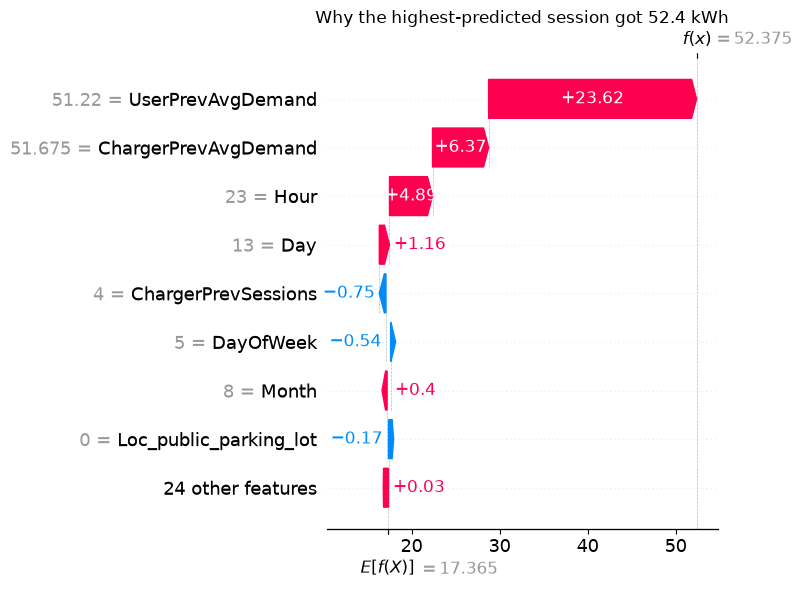

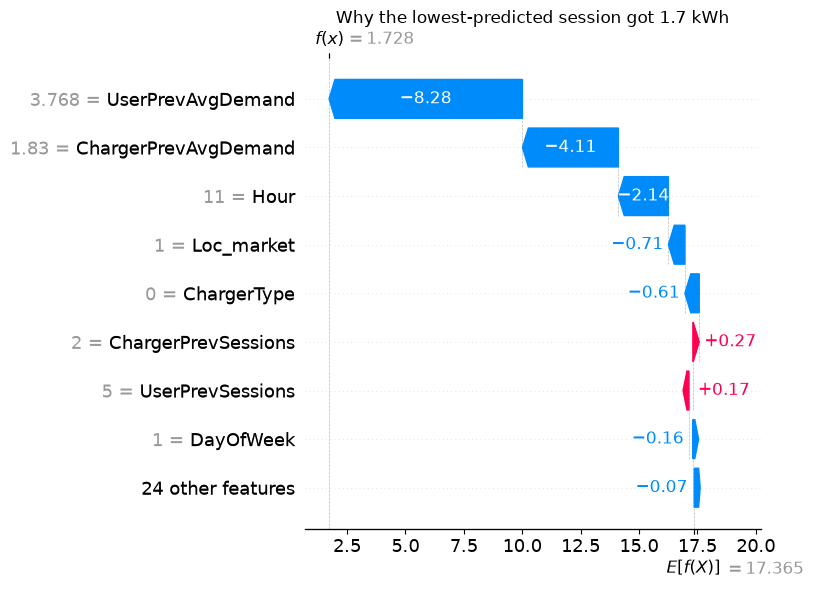

<Figure size 640x480 with 0 Axes>

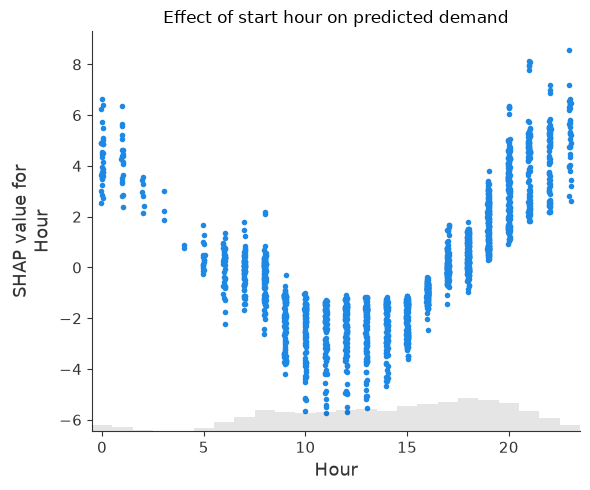

In [3]:
reg_pred = regressor.predict(X_explain)

# SHAP values must add up exactly: average prediction + contributions = prediction
pos = int(np.argmax(reg_pred))
base_value = reg_explanation.base_values[pos]
total = base_value + reg_explanation.values[pos].sum()
print(f"Average prediction {base_value:.2f} + sum of SHAP values = {total:.2f} | model predicted {reg_pred[pos]:.2f}")

# Waterfall plots: why did the highest and lowest predicted sessions get their values?
for label, position in [("highest", int(np.argmax(reg_pred))), ("lowest", int(np.argmin(reg_pred)))]:
    plt.figure()
    shap.plots.waterfall(reg_explanation[position], max_display=9, show=False)
    plt.title(f"Why the {label}-predicted session got {reg_pred[position]:.1f} kWh")
    plt.tight_layout()
    plt.savefig(f"../docs/figures/20_shap_waterfall_{label}.png", dpi=150, bbox_inches="tight")
    plt.show()

# How does the start hour change predictions?
plt.figure()
shap.plots.scatter(reg_explanation[:, "Hour"], show=False)
plt.title("Effect of start hour on predicted demand")
plt.tight_layout()
plt.savefig("../docs/figures/21_shap_hour_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

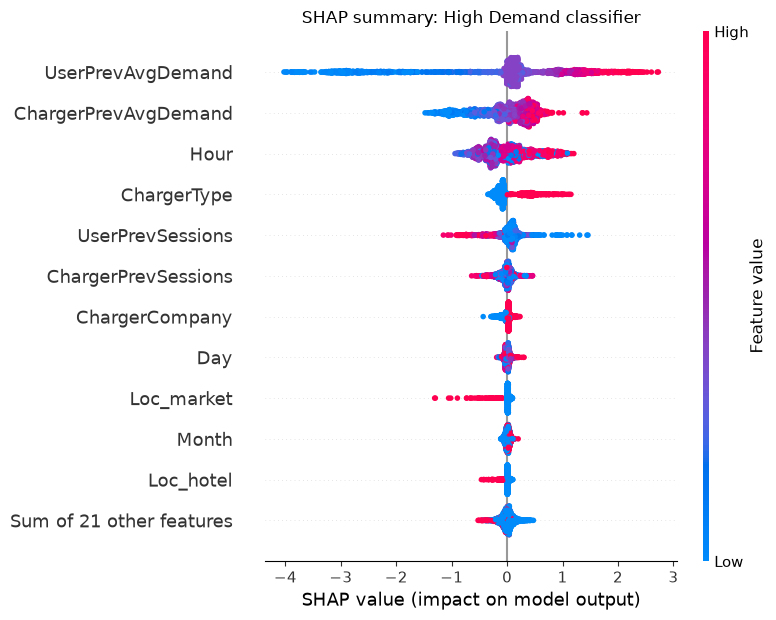

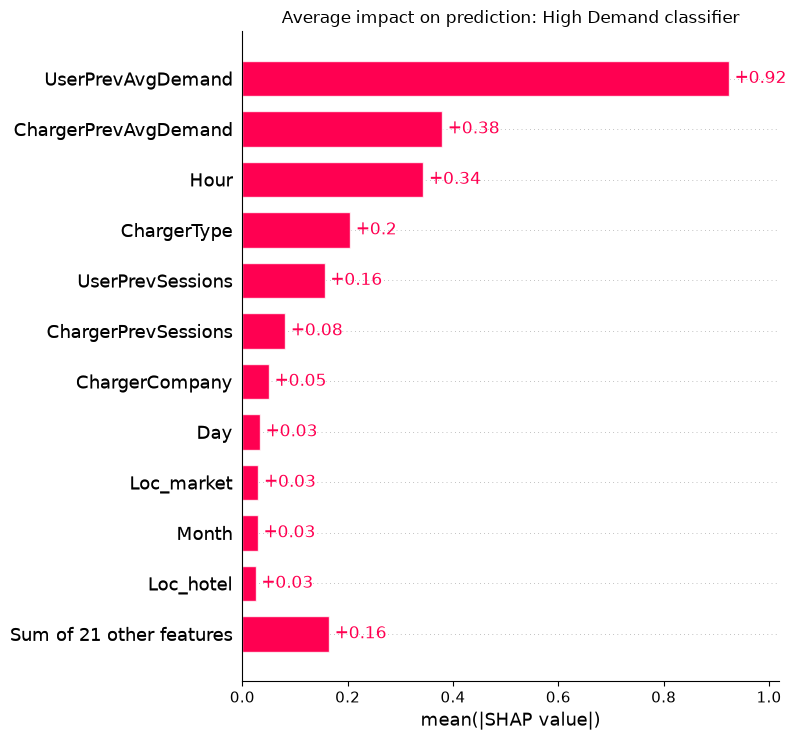

UserPrevAvgDemand       0.924
ChargerPrevAvgDemand    0.379
Hour                    0.344
ChargerType             0.205
UserPrevSessions        0.156
ChargerPrevSessions     0.081
ChargerCompany          0.050
Day                     0.033
dtype: float64


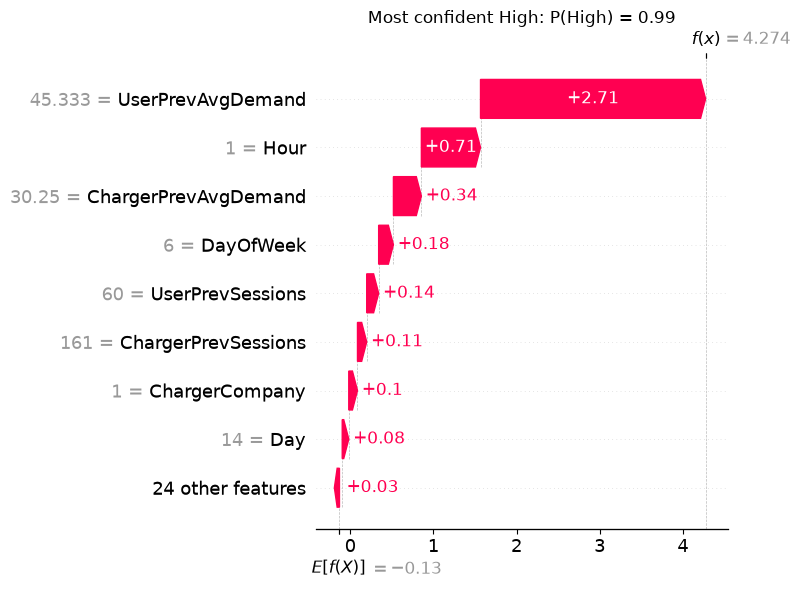

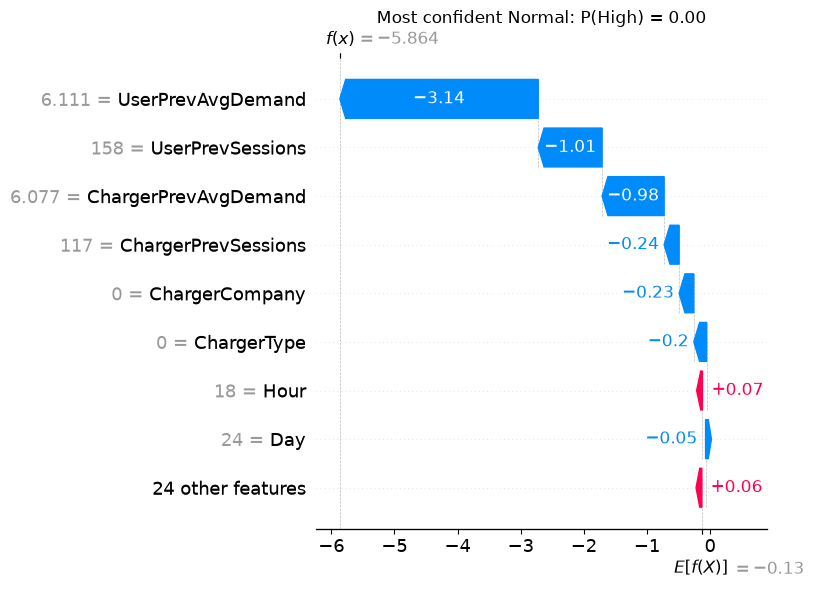

In [4]:
clf_explanation = explain_globally(classifier, X_explain, "High Demand classifier", "22_shap_classification")

clf_importance = pd.Series(np.abs(clf_explanation.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print(clf_importance.head(8).round(3))

# One confident High and one confident Normal prediction
probability_high = classifier.predict_proba(X_explain)[:, 1]
for label, position in [("High", int(np.argmax(probability_high))), ("Normal", int(np.argmin(probability_high)))]:
    plt.figure()
    shap.plots.waterfall(clf_explanation[position], max_display=9, show=False)
    plt.title(f"Most confident {label}: P(High) = {probability_high[position]:.2f}")
    plt.tight_layout()
    plt.savefig(f"../docs/figures/23_shap_classifier_{label.lower()}.png", dpi=150, bbox_inches="tight")
    plt.show()

LIME explanation (feature rule, effect on kWh):
  UserPrevAvgDemand > 17.37                     +9.79
  ChargerPrevAvgDemand > 20.68                  +4.38
  Hour > 19.00                                  +4.25
  Loc_accommodation=0                           +1.29
  Loc_market=0                                  +1.08
  ChargerType=0                                 -1.08
  HasChargerHistory=1                           +0.60
  Loc_camping=0                                 -0.56


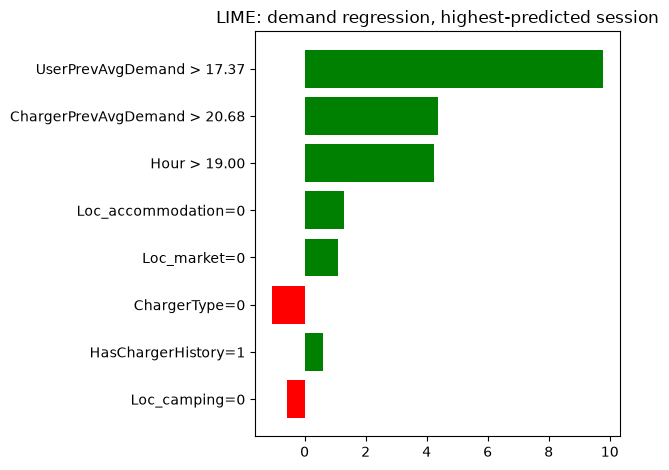

In [5]:
# Binary 0/1 columns (like ChargerType) should be treated as categories, not numbers
binary_positions = [i for i, column in enumerate(FEATURES) if X_train[column].nunique() <= 2]


def make_lime(mode, seed=42):
    return LimeTabularExplainer(
        training_data=X_train.values,
        feature_names=FEATURES,
        categorical_features=binary_positions,
        class_names=["Normal", "High"] if mode == "classification" else None,
        mode=mode,
        random_state=seed,
    )


def predict_demand(data):
    return regressor.predict(pd.DataFrame(data, columns=FEATURES))


def predict_high_probability(data):
    return classifier.predict_proba(pd.DataFrame(data, columns=FEATURES))


# Explain the same session as the highest SHAP waterfall, so the two can be compared
pos = int(np.argmax(reg_pred))
session = X_explain.iloc[pos].values

lime_regression = make_lime("regression")
lime_result = lime_regression.explain_instance(session, predict_demand, num_features=8)

print("LIME explanation (feature rule, effect on kWh):")
for rule, weight in lime_result.as_list():
    print(f"  {rule:45s} {weight:+.2f}")

fig = lime_result.as_pyplot_figure()
plt.title("LIME: demand regression, highest-predicted session")
plt.tight_layout()
fig.savefig("../docs/figures/24_lime_regression.png", dpi=150, bbox_inches="tight")
plt.show()

Model says P(High) = 0.99
  UserPrevAvgDemand > 17.37                     +0.295
  Loc_bus_garage=0                              +0.164
  ChargerPrevAvgDemand > 20.68                  +0.109
  ChargerType=0                                 -0.107
  Loc_accommodation=0                           +0.070
  Loc_market=0                                  +0.061
  Loc_sightseeing=0                             +0.056
  Loc_golf=0                                    +0.042


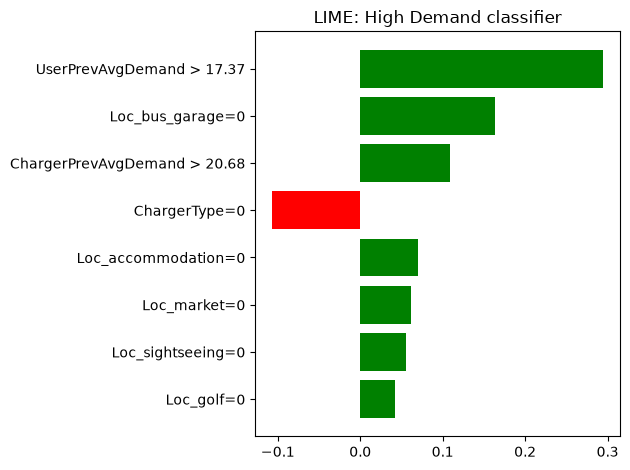

In [6]:
position = int(np.argmax(probability_high))
session = X_explain.iloc[position].values

lime_classification = make_lime("classification")
lime_result = lime_classification.explain_instance(session, predict_high_probability, num_features=8)

print(f"Model says P(High) = {probability_high[position]:.2f}")
for rule, weight in lime_result.as_list():
    print(f"  {rule:45s} {weight:+.3f}")

fig = lime_result.as_pyplot_figure()
plt.title("LIME: High Demand classifier")
plt.tight_layout()
fig.savefig("../docs/figures/25_lime_classification.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
pos = int(np.argmax(reg_pred))

shap_top = pd.Series(reg_explanation.values[pos], index=FEATURES).sort_values(key=np.abs, ascending=False).head(8)
print("SHAP top features for this session (kWh):")
print(shap_top.round(2))

# LIME is random: does it give the same answer with a different seed?
row = X_explain.iloc[pos].values
for seed in (1, 2, 3):
    result = make_lime("regression", seed).explain_instance(row, predict_demand, num_features=5)
    print(f"LIME seed {seed}:", [rule for rule, weight in result.as_list()])

SHAP top features for this session (kWh):
UserPrevAvgDemand         23.62
ChargerPrevAvgDemand       6.37
Hour                       4.89
Day                        1.16
ChargerPrevSessions       -0.75
DayOfWeek                 -0.54
Month                      0.40
Loc_public_parking_lot    -0.17
dtype: float64
LIME seed 1: ['UserPrevAvgDemand > 17.37', 'ChargerPrevAvgDemand > 20.68', 'Hour > 19.00', 'ChargerType=0', 'TOD_Evening=0']
LIME seed 2: ['UserPrevAvgDemand > 17.37', 'Loc_bus_garage=0', 'Hour > 19.00', 'ChargerPrevAvgDemand > 20.68', 'ChargerType=0']
LIME seed 3: ['UserPrevAvgDemand > 17.37', 'ChargerPrevAvgDemand > 20.68', 'Hour > 19.00', 'ChargerType=0', '1.00 < UserPrevSessions <= 28.00']


In [8]:
reg_importance.round(4).to_csv("../models/shap_importance_regression.csv", header=["mean_abs_shap_kwh"])
clf_importance.round(4).to_csv("../models/shap_importance_classification.csv", header=["mean_abs_shap_logodds"])
X_explain.to_csv("../data/processed/explain_sample.csv", index=False)

# Pickle files can fail to load under different library versions, so record which ones we used
model_info = {
    "regressor": type(regressor).__name__,
    "classifier": type(classifier).__name__,
    "python": sys.version.split()[0],
    "scikit-learn": sklearn.__version__,
    "lightgbm": lightgbm.__version__,
    "shap": shap.__version__,
    "n_features": len(FEATURES),
}
with open("../models/model_info.json", "w") as file:
    json.dump(model_info, file, indent=2)

for path in sorted(Path("../models").glob("*.pkl")):
    print(f"{path.name:25s} {path.stat().st_size / 1e6:.2f} MB")

best_classifier.pkl       1.04 MB
best_regressor.pkl        0.85 MB
